In [1]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)

import numpy as np
import pandas as pd
from os import listdir
from os.path import isfile, join
from mhcnames import normalize_allele_name
import mhcnames
import mhcgnomes


# 1. Read data

In [2]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
EXPERIMENT_NAME = 'multiple_single_allele_models'
DATA_PATH = f'{DATA_PATH_BASE}/{EXPERIMENT_NAME}/' #Work laptop

# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu

In [3]:
onlyfiles = [f for f in listdir(DATA_PATH) if isfile(join(DATA_PATH, f))]
ALLELES = []
NOT_NORMALIZED = []
per_allele_train_df = dict()
for file_name in onlyfiles:
    allele_name = file_name.split("#", 1)[1].split('.')[0]
    NOT_NORMALIZED.append(allele_name)
    allele_name = mhcgnomes.parse(allele_name).to_string()
    per_allele_train_df[allele_name] =  pd.read_csv(DATA_PATH + file_name,sep=";")
    ALLELES.append(allele_name)
ALLELES

C:\Users\denkl\AppData\Local\Temp\ipykernel_1100\256977989.py:9: DtypeWarning: Columns (1,9) have mixed types. Specify dtype option on import or set low_memory=False.
  per_allele_train_df[allele_name] =  pd.read_csv(DATA_PATH + file_name,sep=";")
C:\Users\denkl\AppData\Local\Temp\ipykernel_1100\256977989.py:9: DtypeWarning: Columns (1,9) have mixed types. Specify dtype option on import or set low_memory=False.
  per_allele_train_df[allele_name] =  pd.read_csv(DATA_PATH + file_name,sep=";")


['HLA-B*27:05',
 'HLA-DRB1*15:01',
 'HLA-A*02:01',
 'HLA-DRB1*03:01',
 'HLA-DRB1*13:02',
 'HLA-DRB1*13:01',
 'HLA-DRB1*01:03',
 'HLA-DRB1*15:02',
 'HLA-B*07:02',
 'H2-K*b',
 'HLA-B*57:01',
 'HLA-A*01:01',
 'HLA-B*15:02',
 'H2-D*b',
 'HLA-A*24:02',
 'H2-K*d',
 'HLA-DRB1*01:01',
 'HLA-B*40:02',
 'HLA-B*51:01',
 'HLA-B*15:01',
 'HLA-DRB1*07:01',
 'HLA-B*40:01',
 'HLA-A*11:01',
 'HLA-DPA1*01:03/DPB1*04:01',
 'HLA-A*03:01',
 'HLA-DRB1*04:01',
 'HLA-B*44:02',
 'HLA-DRB1*04:04',
 'HLA-DPA1*02:02/DPB1*05:01',
 'H2-AA*b/AB*b',
 'HLA-C*05:01',
 'HLA-A*29:02',
 'HLA-B*44:03',
 'HLA-A*68:02',
 'HLA-C*12:02',
 'HLA-B*08:01',
 'HLA-B*58:01',
 'HLA-DRA*01:01/DRB1*04:01',
 'HLA-DPA1*02:01/DPB1*14:01',
 'HLA-DQ',
 'HLA-DPA1*01:03/DPB1*02:01',
 'HLA-A*02:03',
 'H2-K*k',
 'HLA-DPA1*01:03/DPB1*03:01',
 'H2-D*q',
 'HLA-DQA1*02:01/DQB1*02:02',
 'HLA-A*31:01',
 'HLA-DRB1*11:01',
 'HLA-C*03:04',
 'HLA-DQA1*05:05/DQB1*03:01',
 'HLA-DQA1*03:01/DQB1*03:02',
 'HLA-DPA1*02:01/DPB1*10:01',
 'HLA-A*02:02',
 'HLA-A*0

# 2. Make per length split

In [4]:
from sklearn.model_selection import KFold
MIN_LENGTH = 8
MAX_LENGTH = 30

#leave only binders
def getBindersPeptidesOnly(df):
    result_peptides = df[df['binder'] == 1]['peptide'].values
    return result_peptides
def getNonBindersPeptidesOnly(df):
    result_peptides = df[df['binder'] == 0]['peptide'].values
    return result_peptides

def make_per_length_dict(df, binder_flag):
    lengths = set(df['length'])
    lengths = set([length for length in lengths if length >= MIN_LENGTH and length <= MAX_LENGTH])
    per_length_dict = dict()
    for length in lengths:
        result_peptides = df[(df['binder'] == binder_flag) & (df['length'] == length)]['peptide'].values
        per_length_dict[length] = result_peptides
    return per_length_dict

kf = KFold(n_splits=5, shuffle=True)
def make_per_length_per_KFold_dict(per_length_dict):

    per_length_per_kfold_peptides_train = dict()
    per_length_per_kfold_peptides_test = dict()

    print("Length \t Train/Test for splits", end="")
    for target_length in per_length_dict.keys():
        print(f"\n{target_length}:", end="\t")
        peptides_array = per_length_dict[target_length]
        per_length_per_kfold_peptides_train[target_length] = dict()
        per_length_per_kfold_peptides_test[target_length] = dict()
        if len(peptides_array) > kf.n_splits:
            i = 0
            for train_indexes_b, test_indexes_b in kf.split(peptides_array):
                print("{}/{}\t".format(len(train_indexes_b), len(test_indexes_b)), end="")
                current_train = peptides_array[train_indexes_b]
                current_test = peptides_array[test_indexes_b]
                per_length_per_kfold_peptides_train[target_length][i] = current_train
                per_length_per_kfold_peptides_test[target_length][i] = current_test
                i = i + 1
        else:

            print(f"Not enough peptides of length {target_length}", end="")
    print()
    return per_length_per_kfold_peptides_train , per_length_per_kfold_peptides_test





def addAuxColumns(per_allele_df):
    for allele_name, df in per_allele_df.items():
        df['length'] = df['peptide'].str.len()

per_allele_binders_train = dict()
per_allele_non_binders_train = dict()
per_allele_per_length_binders_train = dict()
per_allele_per_length_non_binders_train = dict()
per_allele_per_length_per_kfold_binders_train = dict()
per_allele_per_length_per_kfold_binders_test = dict()
per_allele_per_length_per_kfold_non_binders_train = dict()
per_allele_per_length_per_kfold_non_binders_test = dict()


for allele_name in ALLELES:
    print(f"Allele {allele_name}")
    df_train = per_allele_train_df[allele_name]
    df_train = df_train.sample(frac=1).reset_index(drop=True)
    per_allele_binders_train[allele_name] = getBindersPeptidesOnly(df_train)
    per_allele_non_binders_train[allele_name] = getNonBindersPeptidesOnly(df_train)
    per_allele_per_length_binders_train[allele_name] = make_per_length_dict(df_train, binder_flag=1)
    per_allele_per_length_non_binders_train[allele_name] = make_per_length_dict(df_train, binder_flag=0)
    print(f"Binders")
    per_allele_per_length_per_kfold_binders_train[allele_name],  per_allele_per_length_per_kfold_binders_test[allele_name] = make_per_length_per_KFold_dict(per_allele_per_length_binders_train[allele_name])
    print(f"Non-binders")
    per_allele_per_length_per_kfold_non_binders_train[allele_name],  per_allele_per_length_per_kfold_non_binders_test[allele_name] = make_per_length_per_KFold_dict(per_allele_per_length_non_binders_train[allele_name])


Allele HLA-B*27:05
Binders
Length 	 Train/Test for splits
8:	664/166	664/166	664/166	664/166	664/166	
9:	22761/5691	22761/5691	22762/5690	22762/5690	22762/5690	
10:	11636/2910	11637/2909	11637/2909	11637/2909	11637/2909	
11:	7686/1922	7686/1922	7686/1922	7687/1921	7687/1921	
12:	3841/961	3841/961	3842/960	3842/960	3842/960	
13:	2306/577	2306/577	2306/577	2307/576	2307/576	
14:	1702/426	1702/426	1702/426	1703/425	1703/425	
15:	1404/352	1405/351	1405/351	1405/351	1405/351	
16:	1157/290	1157/290	1158/289	1158/289	1158/289	
17:	964/242	965/241	965/241	965/241	965/241	
18:	755/189	755/189	755/189	755/189	756/188	
19:	624/157	625/156	625/156	625/156	625/156	
20:	492/123	492/123	492/123	492/123	492/123	
21:	402/101	402/101	402/101	403/100	403/100	
22:	344/86	344/86	344/86	344/86	344/86	
23:	244/62	245/61	245/61	245/61	245/61	
24:	180/45	180/45	180/45	180/45	180/45	
25:	152/38	152/38	152/38	152/38	152/38	
26:	Not enough peptides of length 26
27:	Not enough peptides of length 27
Non-binders
Len

In [5]:
ALLELES

['HLA-B*27:05',
 'HLA-DRB1*15:01',
 'HLA-A*02:01',
 'HLA-DRB1*03:01',
 'HLA-DRB1*13:02',
 'HLA-DRB1*13:01',
 'HLA-DRB1*01:03',
 'HLA-DRB1*15:02',
 'HLA-B*07:02',
 'H2-K*b',
 'HLA-B*57:01',
 'HLA-A*01:01',
 'HLA-B*15:02',
 'H2-D*b',
 'HLA-A*24:02',
 'H2-K*d',
 'HLA-DRB1*01:01',
 'HLA-B*40:02',
 'HLA-B*51:01',
 'HLA-B*15:01',
 'HLA-DRB1*07:01',
 'HLA-B*40:01',
 'HLA-A*11:01',
 'HLA-DPA1*01:03/DPB1*04:01',
 'HLA-A*03:01',
 'HLA-DRB1*04:01',
 'HLA-B*44:02',
 'HLA-DRB1*04:04',
 'HLA-DPA1*02:02/DPB1*05:01',
 'H2-AA*b/AB*b',
 'HLA-C*05:01',
 'HLA-A*29:02',
 'HLA-B*44:03',
 'HLA-A*68:02',
 'HLA-C*12:02',
 'HLA-B*08:01',
 'HLA-B*58:01',
 'HLA-DRA*01:01/DRB1*04:01',
 'HLA-DPA1*02:01/DPB1*14:01',
 'HLA-DQ',
 'HLA-DPA1*01:03/DPB1*02:01',
 'HLA-A*02:03',
 'H2-K*k',
 'HLA-DPA1*01:03/DPB1*03:01',
 'H2-D*q',
 'HLA-DQA1*02:01/DQB1*02:02',
 'HLA-A*31:01',
 'HLA-DRB1*11:01',
 'HLA-C*03:04',
 'HLA-DQA1*05:05/DQB1*03:01',
 'HLA-DQA1*03:01/DQB1*03:02',
 'HLA-DPA1*02:01/DPB1*10:01',
 'HLA-A*02:02',
 'HLA-A*0

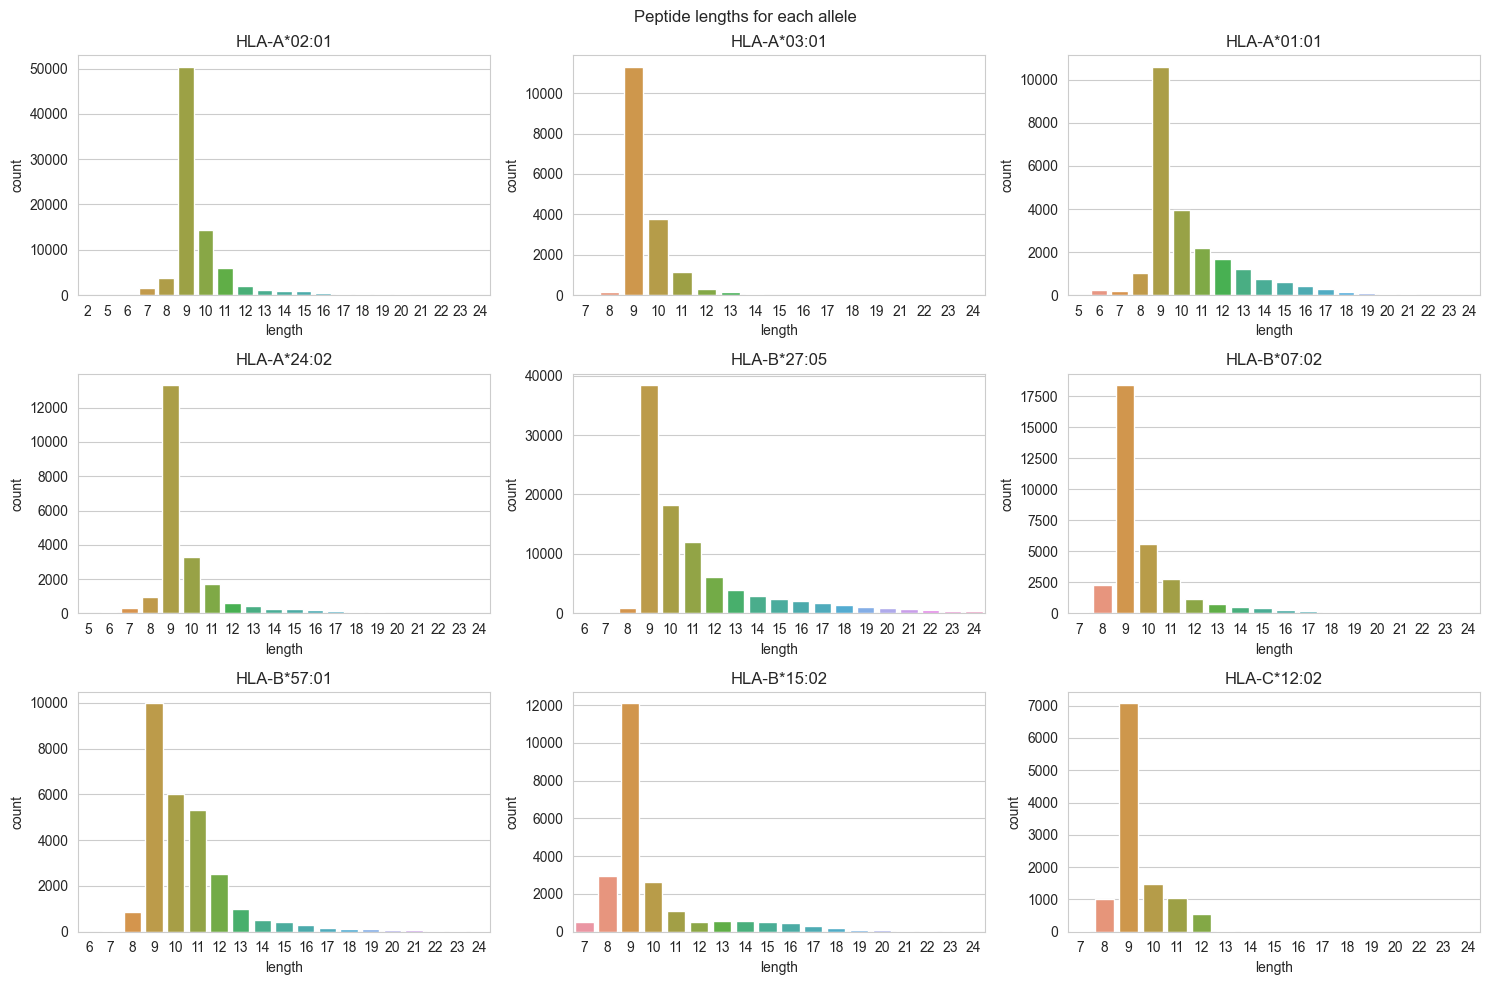

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
class1 = ['HLA-A*02:01',
 'HLA-A*03:01',
 'HLA-A*01:01',
 'HLA-A*24:02',
 'HLA-B*27:05',
 'HLA-B*07:02',
 'HLA-B*57:01',
 'HLA-B*15:02',
 'HLA-C*12:02',]

class2 = ['HLA-DRB1*01:01',
          'HLA-DRB1*04:01',
          'HLA-DRB1*07:01',
          'HLA-DRB1*04:04',
          'HLA-DPA1*01:03/DPB1*04:01',
          'HLA-DPA1*02:02/DPB1*05:01','HLA-DQA1*05:01/DQB1*02:01']

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 10))


for cur_ax, allele_name in zip(axes.flatten(), class1):
    df = per_allele_train_df[allele_name]
    ax = sns.countplot(df[df.length< 25], x='length', ax=cur_ax)
    ax.set(title=f'{allele_name}')
    ax.figure.suptitle(f'Peptide lengths for each allele')
plt.tight_layout()
# ax.set(yscale="log")

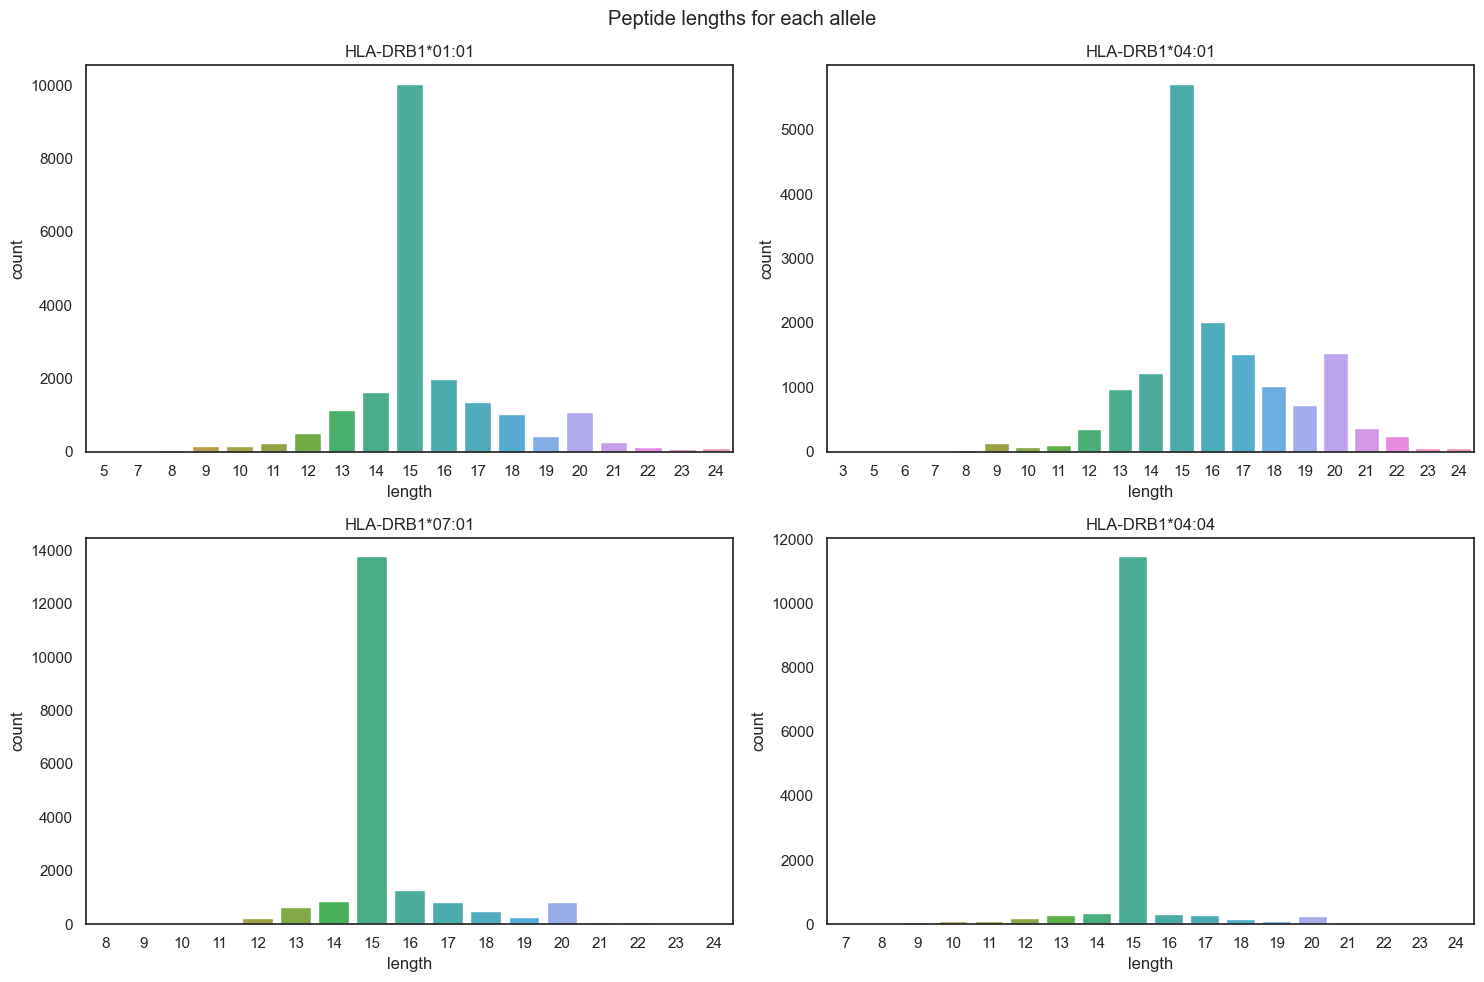

In [55]:
class2 = ['HLA-DRB1*01:01',
 'HLA-DRB1*04:01',
 'HLA-DRB1*07:01',
 'HLA-DRB1*04:04']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))


for cur_ax, allele_name in zip(axes.flatten(), class2):
    df = per_allele_train_df[allele_name]
    ax = sns.countplot(df[df.length< 25], x='length', ax=cur_ax)
    ax.set(title=f'{allele_name}')
    ax.figure.suptitle(f'Peptide lengths for each allele')
plt.tight_layout()

In [8]:
import logomaker
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

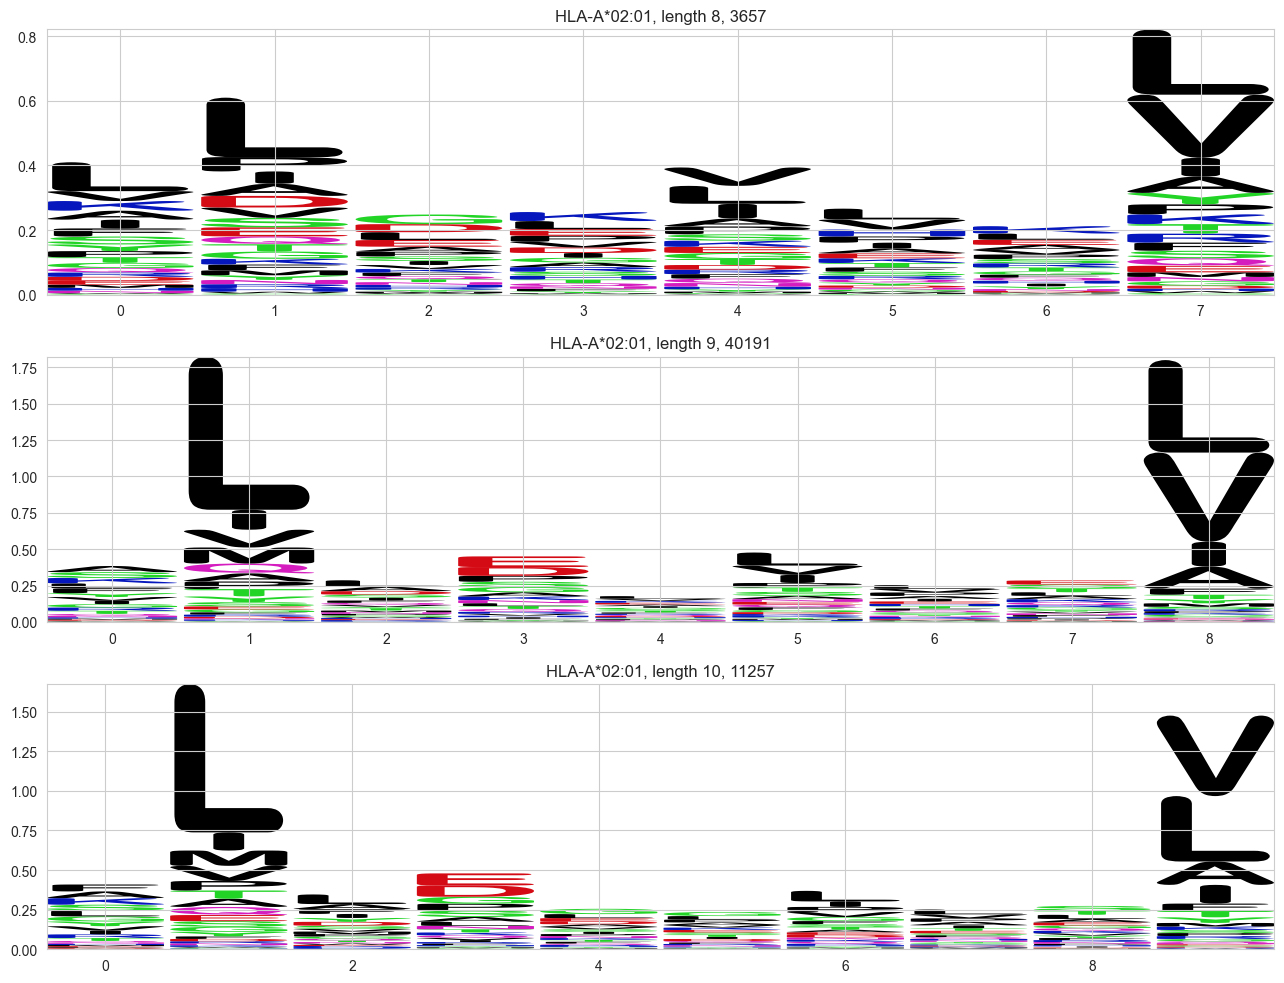

In [9]:
target_allele_name = class1[0]
TARGET_LENGTHS = [8, 9 ,10]

fig, axes = plt.subplots(nrows=len(TARGET_LENGTHS), ncols=1, figsize=(13, 10))
for target_length, cur_ax in zip(TARGET_LENGTHS, axes.flatten()):
    make_logo_for_data(per_allele_per_length_binders_train[target_allele_name][target_length], f"{target_allele_name}, length {target_length}", ax=cur_ax)

plt.tight_layout()

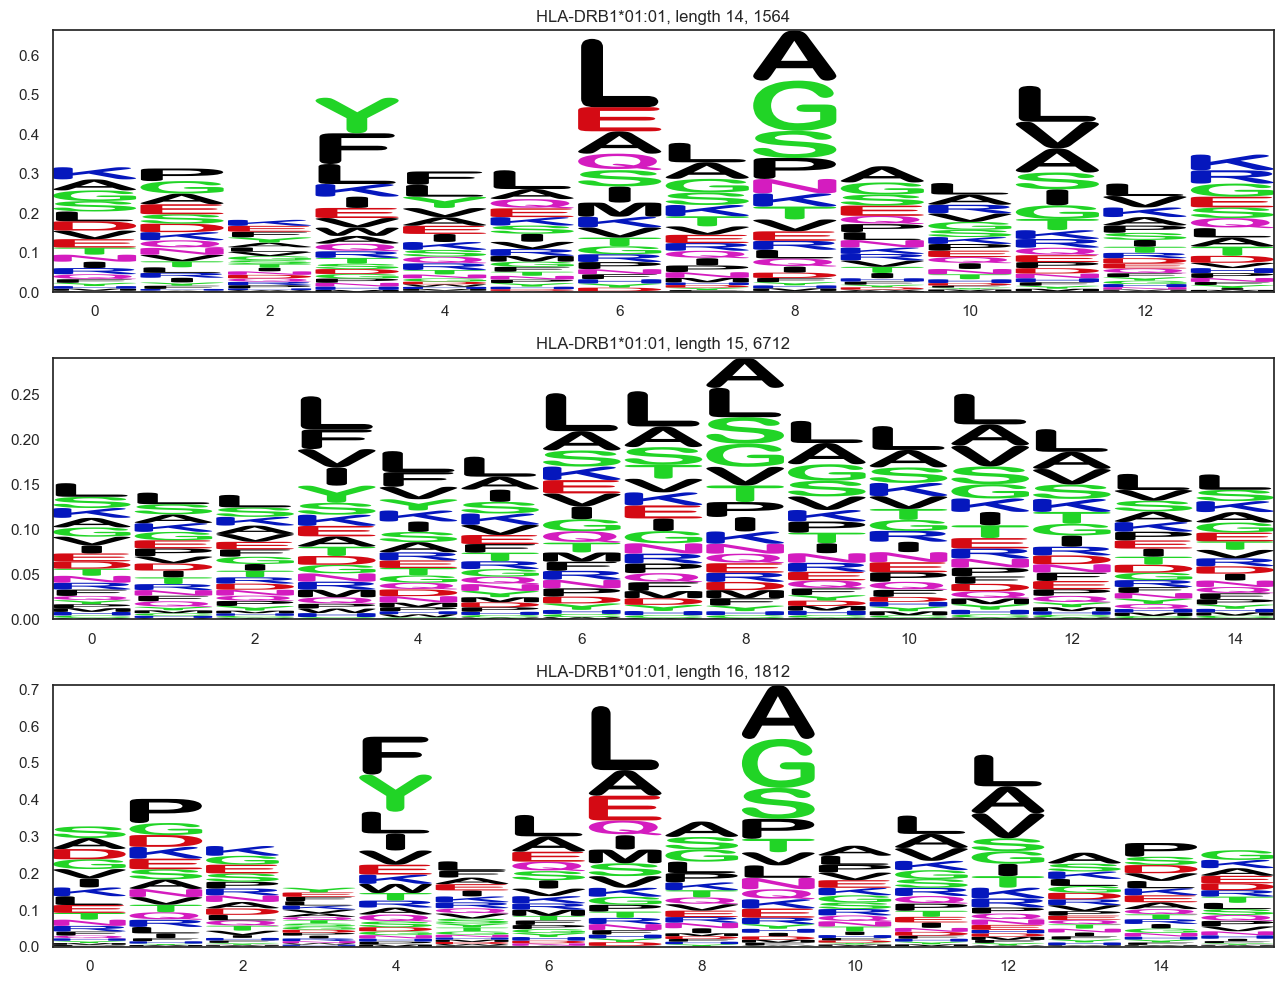

In [58]:
target_allele_name = class2[0]
TARGET_LENGTHS = [14, 15 ,16]

fig, axes = plt.subplots(nrows=len(TARGET_LENGTHS), ncols=1, figsize=(13, 10))
for target_length, cur_ax in zip(TARGET_LENGTHS, axes.flatten()):
    make_logo_for_data(per_allele_per_length_binders_train[target_allele_name][target_length], f"{target_allele_name}, length {target_length}", ax=cur_ax)

plt.tight_layout()

# 3. Save per_length_per_split to files

In [6]:
import os
from collections import defaultdict

TARGET_PATH_TO_FILES = DATA_PATH  + '/per_length_per_kfold_split/'
if not os.path.exists(TARGET_PATH_TO_FILES):
    os.makedirs(TARGET_PATH_TO_FILES)

def save_data(per_allele_per_length_per_kfold_data, data_type=None, dataset_type=None):
    assert data_type in ["binders", "nonbinders"]
    assert dataset_type in ["train", "test"]

    per_allele_dfs = defaultdict(list)
    for allele_name in per_allele_per_length_per_kfold_data.keys():
        for length, per_k_fold_dict in per_allele_per_length_per_kfold_data[allele_name].items():
                for split_num, peptides in per_k_fold_dict.items():
                    df = pd.DataFrame({"peptide":peptides, "length":length, "split": split_num})
                    per_allele_dfs[allele_name].append(df)
        total_df= pd.concat(per_allele_dfs[allele_name])
        target_allele_name = mhcgnomes.parse(allele_name).compact_string(include_species=True).replace("*", "_")
        total_df.to_csv(f'{TARGET_PATH_TO_FILES}{target_allele_name}#{data_type}#{dataset_type}.csv',sep=";", index=False)


save_data(per_allele_per_length_per_kfold_binders_train, "binders", "train")
# save_data(per_allele_per_length_per_kfold_non_binders_train, "nonbinders", "train")
save_data(per_allele_per_length_per_kfold_binders_test, "binders", "test")
# save_data(per_allele_per_length_per_kfold_non_binders_test, "nonbinders", "test")

In [7]:
allele_name

'HLA-DRB3*01:01'

In [13]:
mhcgnomes.parse(mhcgnomes.parse(allele_name).compact_string(include_species=True).replace("*", "-"))

Allele(gene=Gene(species=Species(name='Homo sapiens', mhc_prefix='HLA'), name='C', mutations=()), allele_fields=('12', '02'), annotations=(), mutations=())

In [14]:
per_allele_per_length_per_kfold_binders_test.keys()

dict_keys(['HLA-A*02:01', 'HLA-A*03:01', 'HLA-A*01:01', 'HLA-A*24:02', 'HLA-B*27:05', 'HLA-B*07:02', 'HLA-B*57:01', 'HLA-B*15:02', 'HLA-C*12:02', 'HLA-DRB1*01:01', 'HLA-DRB1*04:01', 'HLA-DRB1*07:01', 'HLA-DRB1*04:04', 'HLA-DPA1*01:03/DPB1*04:01', 'HLA-DPA1*02:02/DPB1*05:01', 'HLA-DQA1*05:01/DQB1*02:01'])

In [15]:
per_allele_per_length_per_kfold_binders_test['HLA-DQA1*05:01/DQB1*02:01']

{8: {0: array(['FLRYAVVL', 'HVDDMPNA', 'MRYVASYL', 'MATPLLMQ'], dtype=object),
  1: array(['EALPKQSV', 'TPHLHSIL', 'VHLTPEEK', 'IRTIELDG'], dtype=object),
  2: array(['NLKVKVLF', 'VFLENVIR', 'RDLAAVNL'], dtype=object),
  3: array(['FVFADVIR', 'DPAAIIHD', 'FTKVKPLL'], dtype=object),
  4: array(['FDGDEIFH', 'LALNEDLR', 'LPMGALPQ'], dtype=object)},
 9: {0: array(['FDGDEIFHV', 'KLRQPFFQK', 'HGIDPTGTY', 'YFAERVTSL', 'LPSTEDVYD',
         'FGEEAEEEA', 'VTELHVISY', 'QLDRISVYY', 'QENSRVIVM', 'YIDEQFERY',
         'GAVEAISDR', 'DFKIRTIEL', 'PIVGILAGL', 'IQVYEGERA', 'RYRPGTVAL',
         'VGEYRAVTE', 'LAAARLAAA', 'DFDGDEIFH', 'IFSIREVSF', 'KASGTLREY',
         'LPHHRVIEV', 'WIKEKIYVL', 'YTAVVPLVY'], dtype=object),
  1: array(['FEVVTPEEQ', 'RRFMQTFVL', 'ELLIRKLPF', 'AKDVKFGAD', 'MTHNLLLNY',
         'KWEAARVAE', 'RKWEAAHVA', 'IINSSITTK', 'DLKEKKEVV', 'ISTDQDHFL',
         'NVDPVQHTY', 'DLNKRVQDL', 'HLTPEEKSA', 'LMAHMASKE', 'KENPLQFKF',
         'DTDSEEEIR', 'MRMATPLLM', 'IVADHVASY', 'MIEPRTLQY', 